# Is the new prompt actually better? Evals with error bars

You change a prompt, rerun your eval, and the score moves a few points. Is the new prompt better, or did you get a lucky run?

A single score cannot answer that, for two reasons. An eval is a sample of cases, so a different sample would give a different score. And the model's answers vary from run to run: Claude Haiku 5.5 rejects a `temperature` setting, so you cannot pin a run down and repeat it. Teams that compare two bare numbers ship changes that did nothing and throw away changes that worked.

This cookbook builds a small set of tools that answers the question properly, and uses them on a worked example: a refund desk, and two changes to its system prompt. One change adds a single sentence. The other rewrites the whole policy as a checklist. One of them turns out to matter and the other does not, and a first eval of 100 cases is not enough to be sure of either. The statistics come from Evan Miller's paper [Adding Error Bars to Evals](https://arxiv.org/abs/2411.00640), reduced to the handful of functions you need for a prompt comparison.

By the end of this cookbook, you'll be able to:

- Put a confidence interval on an eval score, and see how wide it is at the size of a typical eval
- Compare two prompts on the same cases, and read the interval of the difference as better, worse, or not yet known
- Separate the noise between runs from the noise between cases, and decide which one to spend money on
- Work out how many cases a comparison needs, run them at half price with the Message Batches API, and turn the result into a release gate

## Prerequisites and setup

**Required knowledge**

- Python, and the basic shape of an eval: cases with expected answers and a score
- What a mean and a standard deviation are

**Required tools**

- Python 3.11 or later
- An Anthropic API key ([get one here](https://platform.claude.com/settings/keys)) in a `.env` file as `ANTHROPIC_API_KEY`

**Recommended**

- An eval of your own to try the functions on afterwards

The notebook reads the recorded results of a full run from `results/`, so the analysis reproduces exactly. It still needs the API key: one cell calls the API live on five cases, which costs less than a cent. Set `RUN_FULL_EVAL=1` to rerun the whole eval yourself; the recorded run cost $0.57 through the Message Batches API.

In [1]:
%%capture
%pip install -U "anthropic>=2.0.0" numpy pandas matplotlib python-dotenv

In [2]:
import inspect
import os
from pathlib import Path

import anthropic
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from batch_runner import (
    build_requests,
    collect_batch,
    cost_usd,
    load_rows,
    run_now,
    save_rows,
    scores_by_prompt,
    submit_batch,
    wait_for_batch,
)
from dotenv import load_dotenv
from error_bars import (
    bootstrap_diff_ci,
    detectable_effect,
    estimate_mean,
    mean_ci,
    p_text,
    paired_diff_ci,
    per_case,
    projected_margin,
    required_cases,
    sign_test_p,
    unpaired_diff_ci,
    variance_components,
    verdict,
)
from IPython.display import Code, display
from refund_task import DEFAULT_SENTENCE, PROMPTS, load_cases, render_ticket, ruling

load_dotenv()
client = anthropic.Anthropic()

MODEL = "claude-haiku-5-5"
RUN_FULL_EVAL = os.environ.get("RUN_FULL_EVAL") == "1"
RECORDED = Path("results/main.jsonl")
RERUN = Path("results/rerun.jsonl")


def show_source(function) -> Code:
    """Display a function from the cookbook's modules, so the code is on the page."""
    return Code(inspect.getsource(function), language="python")

The reusable code lives in three small modules next to this notebook, each with offline tests:

- `refund_task.py` is the example task: the cases, the policy, and the prompts
- `error_bars.py` is the statistics, in the standard library and NumPy
- `batch_runner.py` sends the eval to Claude and grades the answers

The notebook imports them and shows each function at the point where it is used.

## The task: one refund policy, three prompts

Northwind Outfitters is a made-up outdoor shop. A refund request arrives as an order record plus the customer's message, and the model has to choose one of three decisions: `approve`, `deny`, or `escalate` to a specialist.

In [3]:
cases = load_cases(Path("data/cases.jsonl"))
example = cases[4]

print(f"{len(cases)} cases\n")
print(render_ticket(example))
print("\nCorrect decision and the rule behind it:", ruling(example))

600 cases

ORDER RECORD
Order on file: yes
Item: handheld radio (electronics)
Quantity: 2
Unit price: $230
Final sale: no
Delivered: 8 August 2026
Package opened: yes
Plus member: no
Previous refunds: 11 May 2026, 9 July 2026

REFUND REQUEST
Received: 13 August 2026
Reason: changed mind
Customer message: "It doesn't suit me after all."

Correct decision and the rule behind it: ('deny', 'opened_electronics')


Nobody labelled these cases by hand. Each case is generated as a set of order facts, and the correct decision comes from the policy written as code. When the model disagrees with the label, the model is wrong, and the dataset never is. That matters here, because label noise would add a third source of error to the two this cookbook is about.

This is the whole policy:

In [4]:
show_source(ruling)

def ruling(case: Case) -> tuple[str, str]:
    """The policy as code: the correct decision and the name of the rule that produced it."""
    if not case.order_on_file:
        return "escalate", "no_order_on_file"
    if case.recent_refunds >= REPEAT_REFUND_LIMIT:
        return "escalate", "repeat_refunds"
    if case.category == "gift_card":
        return "deny", "gift_card"

    days = case.days_since_delivery
    if case.reason in SELLER_FAULT:
        if case.category == "grocery":
            limit, too_late = GROCERY_REPORT_DAYS, "grocery_reported_late"
        elif case.reason == "damaged_in_transit":
            limit, too_late = DAMAGE_REPORT_DAYS, "damage_reported_late"
        else:
            limit, too_late = SELLER_FAULT_DAYS, "seller_fault_too_late"
        if days > limit:
            defective_electronics = case.reason == "defective" and case.category == "electronics"
            if defective_electronics and days <= WARRANTY_DAYS:
                return "escalate", "warranty"
            return "deny", too_late
    else:
        if case.final_sale or case.category == "grocery":
            return "deny", "not_returnable"
        if case.category == "electronics" and case.opened:
            return "deny", "opened_electronics"
        window = PLUS_CHANGE_OF_MIND_DAYS if case.plus_on_delivery else CHANGE_OF_MIND_DAYS
        if days > window:
            return "deny", "outside_window"

    if case.order_line_usd > SIGN_OFF_ABOVE_USD:
        return "escalate", "needs_sign_off"
    return "approve", "eligible"

The generator draws most day counts, order totals, and dates from narrow bands around the policy's thresholds (day 30 and day 31, an order line of $400 and of $401), because that is where a careless reader goes wrong.

Now the prompts. The first, **`draft`**, is the policy the way a policy team writes it:

In [5]:
print(PROMPTS["draft"])

You handle refund requests for Northwind Outfitters.

Refund policy

We want refunds to be easy. Customers who change their mind can return most items within 30 days of delivery. Plus members get 45 days, as long as they joined on or before the day the order was delivered. Opened electronics cannot be returned for a change of mind, and neither can groceries or anything bought as final sale. When we sent the wrong item, or the item arrived damaged or is defective, the customer is not at fault, so we accept those requests for 60 days after delivery, final-sale items included. Two cases are tighter. Damage in transit has to be reported within 14 days of delivery, because that is how long the carrier gives us to claim. Groceries are perishable, so any problem with a grocery item, damage in transit included, has to be reported within 7 days. Defective electronics that are past the 60 days but within 365 days of delivery are covered by the manufacturer's warranty and not by us, so a speciali

Read it as the model would, and ask what it says about a request that falls outside every window. A defective jacket reported after 70 days is not accepted, but the draft never says what to do with it instead. A person reads "not accepted" as "denied" without noticing the step. A gap like this is easy to ship.

The second prompt, **`prose`**, is the draft plus one sentence. The sentence has two parts: it limits the specialist to the situations the policy names, and it says that a request the policy does not allow is denied.

In [6]:
print(DEFAULT_SENTENCE.strip())

A specialist is only for the situations named here: a request that this policy does not allow is denied.


The third prompt, **`procedure`**, is a larger change: the same policy rewritten as an ordered checklist in which every branch ends in an explicit decision. It is the kind of rewrite you would make expecting a better score.

In [7]:
print(PROMPTS["procedure"])

You handle refund requests for Northwind Outfitters.

Refund policy

Work through these checks in order and stop at the first one that gives a decision.

1. The order is not on file: escalate.
2. Count the previous refunds issued in the last 90 days. 3 or more: escalate.
3. The item is a gift card: deny.
4. Count the days from delivery to the request.
5. The reason is wrong item, damaged in transit, or defective. The time limit is 7 days for a grocery item; otherwise 14 days for damage in transit; otherwise 60 days.
   - Within the limit: go to step 7.
   - Past the limit, the item is electronics, the reason is defective, and it is 365 days or fewer since delivery: escalate (manufacturer's warranty).
   - Otherwise: deny.
6. The reason is changed mind:
   - The item is final sale, a grocery item, or opened electronics: deny.
   - The window is 30 days, or 45 days if the customer became a Plus member on or before the delivery date. Past the window: deny.
   - Otherwise: go to step 7.
7.

So there are two changes to judge, and the rest of the notebook treats them the same way:

1. **Add the sentence**: `draft` to `prose`
2. **Rewrite as a procedure**: `prose` to `procedure`

## Step 1: Ask Claude

One request per attempt: the prompt goes in `system`, the ticket in the user turn, and [structured outputs](https://platform.claude.com/docs/en/build-with-claude/structured-outputs) constrain the answer to one of the three decisions, so grading is a string comparison. The `custom_id` records which prompt, case, and run the attempt belongs to. Batch results come back in any order, and the id is how each answer finds its case.

In [8]:
show_source(build_requests)

def build_requests(
    cases: list[Case],
    prompts: dict[str, str],
    runs: int,
    model: str,
    effort: str = "low",
    max_tokens: int = 4096,
) -> list[dict]:
    """Every prompt on every case, `runs` times. The `custom_id` says which attempt it is."""
    return [
        {
            "custom_id": SEPARATOR.join([name, case.case_id, str(run)]),
            "params": {
                "model": model,
                "max_tokens": max_tokens,
                "system": system_prompt,
                "messages": [{"role": "user", "content": render_ticket(case)}],
                "output_config": {
                    "effort": effort,
                    "format": {"type": "json_schema", "schema": DECISION_SCHEMA},
                },
            },
        }
        for name, system_prompt in prompts.items()
        for case in cases
        for run in range(runs)
    ]

Before spending anything on a full run, send five cases through the regular Messages API to see that the plumbing works. `run_now` takes the same request list a batch would.

In [9]:
sample = cases[:5]
live_rows = run_now(client, build_requests(sample, PROMPTS, runs=1, model=MODEL))

expected = {case.case_id: ruling(case)[0] for case in sample}
live = pd.DataFrame(live_rows).pivot(index="case_id", columns="prompt", values="decision")
live["expected"] = live.index.map(expected)
live[["expected", *PROMPTS]]

prompt,expected,draft,prose,procedure
case_id,,,,
case-0001,escalate,escalate,escalate,escalate
case-0002,approve,approve,approve,approve
case-0003,escalate,escalate,escalate,escalate
case-0004,deny,deny,deny,deny
case-0005,deny,deny,deny,deny


One row per case, one column per prompt. This is too few cases to say anything about the prompts. It only shows that requests go out and decisions come back.

## Step 2: Read the eval the usual way

The rest of the notebook works from a recorded run of all 600 cases, three runs for each prompt. `scores_by_prompt` grades it into one array per prompt, shaped `(cases, runs)`, with a 1 for a correct decision.

To begin, pretend you only have what a first eval usually is: **100 cases, run once**.

In [10]:
rows = load_rows(RECORDED)
scores, left_out = scores_by_prompt(rows, cases)
n_cases, n_runs = scores["draft"].shape
print(f"recorded: {n_cases} cases x {n_runs} runs per prompt, {len(left_out)} left out\n")

FIRST = slice(0, 100)  # the first 100 cases
once = {name: scores[name][FIRST, 0] for name in PROMPTS}  # their first run only

for name in PROMPTS:
    print(f"{name:>9}: {once[name].mean():.0%}")

recorded: 600 cases x 3 runs per prompt, 0 left out

    draft: 92%
    prose: 98%
procedure: 98%


Read as bare numbers, the story is simple: the sentence is worth six points, and the rewrite as a procedure changes nothing. The next steps show how little these 100 cases establish about either claim.

## Step 3: Put error bars on one score

Those 100 cases are a sample of all the refund requests the desk will ever see. The score on the sample estimates the score on all of them, and the central limit theorem says how far off it is likely to be: the standard error is the spread between cases divided by the square root of the number of cases. A 95% confidence interval is the score plus or minus 1.96 standard errors.

In [11]:
show_source(estimate_mean)

def estimate_mean(values: NDArray[np.float64], confidence: float = 0.95) -> Estimate:
    """The mean of one number per case, with an interval from the central limit theorem:
    the standard error is the spread between cases divided by the square root of their count."""
    if len(values) < 2:
        raise ValueError("an interval needs at least two cases")
    mean = float(values.mean())
    standard_error = float(values.std(ddof=1)) / sqrt(len(values))
    half_width = _NORMAL.inv_cdf(0.5 + confidence / 2) * standard_error
    return Estimate(mean, mean - half_width, mean + half_width, standard_error, len(values))

In [12]:
for name in PROMPTS:
    estimate = mean_ci(once[name])
    print(f"{name:>9}: {estimate}   plus or minus {estimate.margin:.1%}")

    draft: 92.0% (86.7% to 97.3%)   plus or minus 5.3%
    prose: 98.0% (95.2% to 100.8%)   plus or minus 2.8%
procedure: 98.0% (95.2% to 100.8%)   plus or minus 2.8%


At 100 cases the `draft` score is known to about plus or minus 5 points. Its interval overlaps the other two, so reading the scores one at a time cannot even confirm the six-point gap.

The other two intervals run past 100%, which no score can reach. The formula assumes the sample mean is roughly normal, and that fails when a score is close to 0% or 100% on few cases: two wrong answers in 100 carry very little information about how often failures happen. A score of exactly 100% would get an interval of zero width. Treat an interval this close to the ceiling as rough.

## Step 4: Run the same prompt twice

How much of that uncertainty is the model simply answering differently on another day? Compare the `draft` prompt with itself: the same 100 cases, first run against second run. Nothing changed between them.

In [13]:
first_run, second_run = scores["draft"][FIRST, 0], scores["draft"][FIRST, 1]
flipped = int((first_run != second_run).sum())

print(f"draft, first run:  {first_run.mean():.0%}")
print(f"draft, second run: {second_run.mean():.0%}")
print(f"cases that changed outcome between the two runs: {flipped} of {len(first_run)}")

draft, first run:  92%
draft, second run: 93%
cases that changed outcome between the two runs: 7 of 100


The same prompt on the same cases scored 92% and then 93%, and 7 of the 100 cases changed outcome between the runs. The total moved by one point because flips in both directions mostly cancelled. That is the noise floor of this eval at this size, and any difference between two prompts has to be judged against it. Keep the 7 in mind: in the next step two different prompts will disagree on 8 cases.

## Step 5: Compare on the same cases

Steps 2 and 3 compared scores as if each came from different cases. They did not: every prompt answered the same 100 tickets. That allows a sharper question. For each case, did the change make the answer better, worse, or leave it the same?

Here is that table for the first change, adding the sentence.

In [14]:
def outcome_table(before: np.ndarray, after: np.ndarray, names: tuple[str, str]) -> pd.DataFrame:
    labels = {1.0: "right", 0.0: "wrong"}
    return pd.crosstab(
        pd.Categorical(pd.Series(before).map(labels), ["right", "wrong"]),
        pd.Categorical(pd.Series(after).map(labels), ["right", "wrong"]),
        rownames=[names[0]],
        colnames=[names[1]],
        dropna=False,
    )


outcome_table(once["draft"], once["prose"], ("draft", "prose"))

prose,right,wrong
draft,,
right,91,1
wrong,7,1


Most cases sit on the diagonal, where both prompts were right or both were wrong. Those cases say nothing about which prompt is better. All the evidence is in the other two cells, the cases that only one prompt got right.

A paired comparison uses exactly that. Take the per-case difference, candidate minus baseline, and put an interval on its mean. Difficulty that both prompts share cancels out of every difference.

In [15]:
show_source(paired_diff_ci)

def paired_diff_ci(baseline: ArrayLike, candidate: ArrayLike, confidence: float = 0.95) -> Estimate:
    """Candidate minus baseline, measured on the same cases.

    Each case contributes one difference, so difficulty that both prompts share cancels.
    How much tighter this is than comparing two separate scores depends on how often the
    prompts pass and fail the same cases, which is something to measure, not assume.
    """
    before, after = per_case(baseline), per_case(candidate)
    if before.shape != after.shape:
        raise ValueError("a paired comparison needs the same cases in the same order")
    return estimate_mean(after - before, confidence)

When only a handful of cases differ, the normal approximation behind that interval is shaky. `sign_test_p` is an exact check to read next to it: if the prompts were equally good on every case, each case they split on would be a coin flip. It asks a slightly different question from the interval (how many cases moved each way, not how far the average moved) and it errs on the cautious side, so the two can disagree near the 0.05 line.

In [16]:
show_source(sign_test_p)

def sign_test_p(baseline: ArrayLike, candidate: ArrayLike) -> float:
    """Exact two-sided p-value for "neither prompt is better", from the cases they split on.

    Only cases where one prompt beat the other carry evidence. If the prompts were equally
    good on every case, each such case would be a coin flip, so the count of wins is
    binomial and needs no approximation. Read it next to the interval when only a handful
    of cases differ.

    It asks a slightly different question from the interval: how many cases moved each way,
    not by how much the average moved. It is also on the cautious side, as exact tests are.
    So the two can disagree near the 0.05 line.
    """
    before, after = per_case(baseline), per_case(candidate)
    wins, losses = int((after > before).sum()), int((after < before).sum())
    split = wins + losses
    if split == 0:
        return 1.0
    one_tail = sum(comb(split, k) for k in range(min(wins, losses) + 1)) / 2**split
    return min(1.0, 2 * one_tail)

In [17]:
CHANGES = {"add the sentence": ("draft", "prose"), "rewrite as a procedure": ("prose", "procedure")}


def report(before: np.ndarray, after: np.ndarray) -> None:
    separate, paired = unpaired_diff_ci(before, after), paired_diff_ci(before, after)
    split = int((per_case(before) != per_case(after)).sum())
    print(f"  two separate scores: {separate:+.1%}")
    print(f"  paired by case:      {paired:+.1%}   {paired.p_text}")
    print(
        f"  exact sign test on the {split} cases they split on: {p_text(sign_test_p(before, after))}"
    )
    print(f"  verdict from the interval: {verdict(paired)}")


for change, (baseline, candidate) in CHANGES.items():
    print(f"{change}: {baseline} -> {candidate}, 100 cases, 1 run")
    report(once[baseline], once[candidate])
    print()

add the sentence: draft -> prose, 100 cases, 1 run
  two separate scores: +6.0% (-0.0% to +12.0%)
  paired by case:      +6.0% (+0.6% to +11.4%)   p = 0.031
  exact sign test on the 8 cases they split on: p = 0.070
  verdict from the interval: better

rewrite as a procedure: prose -> procedure, 100 cases, 1 run
  two separate scores: +0.0% (-3.9% to +3.9%)
  paired by case:      +0.0% (-2.8% to +2.8%)   p = 1.000
  exact sign test on the 2 cases they split on: p = 1.000
  verdict from the interval: inconclusive



**Adding the sentence.** Pairing narrowed the interval enough to move its low end from just below zero to just above, so the interval's verdict is `better`. But look at what that rests on. The two prompts split on 8 cases, 7 one way and 1 the other, and the exact test on those 8 gives p = 0.070, on the other side of the usual 0.05 line. When two reasonable methods land on opposite sides of the line, the result is borderline. Even taken at face value, the interval says the sentence is worth somewhere between half a point and eleven.

**Rewriting as a procedure.** The scores are identical and the difference is zero, which is tempting to read as "no effect". The interval says something weaker: the rewrite could be up to 2.8 points better or 2.8 points worse. *No difference seen* is not *no difference*. If you made this change for readability and wanted assurance that it costs nothing, 100 cases cannot give it.

How much pairing helps depends on how often two prompts pass and fail the same cases. Here it took about a tenth off the first interval and more than a quarter off the second. On evals where the same cases are hard for everyone, which is common when comparing models on a public benchmark, it takes off much more. Keep the paired analysis as the default: it costs nothing, and when both prompts ran on the same cases it is the correct interval.

## Step 6: More runs, or more cases?

There are two ways to buy a tighter interval: run each case more times, or add cases. For the same number of requests, new cases always win, because a new case averages down both kinds of noise and a rerun only one. So the question is narrower: when cases are expensive, for example because each needs a reference answer written by a person, how much do reruns buy? That depends on how much of the noise is between runs, and three runs per case are enough to measure it. `variance_components` splits the spread of the per-case differences into a part that persists between cases and a part that changes from run to run.

In [18]:
display(show_source(variance_components), show_source(projected_margin))

def variance_components(scores: ArrayLike) -> tuple[float, float]:
    """Split the spread of `(cases, runs)` scores into (between cases, between runs).

    The variance of the eval score is `(between_cases + between_runs / runs) / cases`, so
    the two numbers say what another case buys you and what another run buys you. This
    assumes the runs of a case are interchangeable: run 2 is not systematically different
    from run 1.
    """
    array = np.asarray(scores, dtype=float)
    if array.ndim != 2 or array.shape[1] < 2:
        raise ValueError("splitting the variance needs at least two runs per case")
    between_runs = float(array.var(axis=1, ddof=1).mean())
    case_means_variance = float(array.mean(axis=1).var(ddof=1))
    between_cases = max(case_means_variance - between_runs / array.shape[1], 0.0)
    return between_cases, between_runs

def projected_margin(
    between_cases: float, between_runs: float, cases: int, runs: int, confidence: float = 0.95
) -> float:
    """The plus-or-minus an eval of `cases` x `runs` would have, given `variance_components`."""
    half_width = _NORMAL.inv_cdf(0.5 + confidence / 2)
    return half_width * sqrt((between_cases + between_runs / runs) / cases)

The split below is for the first change, `prose` minus `draft`. Run 1 of one prompt is lined up with run 1 of the other only for bookkeeping: the runs are independent API calls, so any other line-up would estimate the same two numbers.

In [19]:
differences = scores["prose"] - scores["draft"]  # per case and run, candidate minus baseline
between_cases, between_runs = variance_components(differences)
print(f"variance between cases: {between_cases:.4f}")
print(f"variance between runs:  {between_runs:.4f}")

right = scores["draft"].sum(axis=1)  # how many of its three runs each case got right
print(
    f"\ndraft: {int((right == 3).sum())} cases right in all three runs, "
    f"{int((right == 0).sum())} wrong in all three, {int(((right > 0) & (right < 3)).sum())} mixed\n"
)

plans = pd.DataFrame(
    [
        {
            "cases": n_cases,
            "runs": n_runs,
            "requests per prompt": n_cases * n_runs,
            "margin": f"plus or minus {projected_margin(between_cases, between_runs, n_cases, n_runs):.1%}",
        }
        for n_cases, n_runs in [(100, 1), (100, 3), (300, 1), (100, 6), (600, 1), (600, 3)]
    ]
)
plans

variance between cases: 0.0342
variance between runs:  0.0383

draft: 530 cases right in all three runs, 19 wrong in all three, 51 mixed



,cases,runs,requests per prompt,margin
0,100,1,100,plus or minus 5.3%
1,100,3,300,plus or minus 4.2%
2,300,1,300,plus or minus 3.0%
3,100,6,600,plus or minus 3.9%
4,600,1,600,plus or minus 2.2%
5,600,3,1800,plus or minus 1.7%


Run-to-run noise is the larger part here: a little over half of the variance of a single-run difference comes from the model answering differently on a rerun. The second line of output shows it directly. Of the 70 cases the `draft` prompt ever got wrong, 51 were right in at least one of the three runs.

The table shows both points. At equal cost, cases win: 300 requests per prompt buy plus or minus 4.2% as 100 cases run three times, and plus or minus 3.0% as 300 cases run once. And because so much of the noise is between runs, reruns are worth having when cases are the scarce resource: three runs take the 100-case margin from 5.3% to 4.2% with no new labelling. On an eval where the model answers the same way every time, those reruns would buy nothing.

The last row is the design of the recorded run. Its margin is the measured one, because the two variances were estimated from that same run. The other rows are projections from it.

## Step 7: How many cases do you need?

Before running anything large, decide what the smallest improvement worth shipping is, and work out how many cases it takes to see it. `required_cases` is the standard power calculation for a paired comparison: the number of cases at which a real effect of that size produces an interval clear of zero 80% of the time.

In [20]:
show_source(required_cases)

def required_cases(
    smallest_effect: float,
    sd_of_differences: float,
    power: float = 0.8,
    confidence: float = 0.95,
) -> int:
    """Cases needed for a paired comparison to detect `smallest_effect` with the given power."""
    if smallest_effect == 0:
        raise ValueError("no number of cases can detect an effect of zero")
    z_total = _NORMAL.inv_cdf(0.5 + confidence / 2) + _NORMAL.inv_cdf(power)
    return ceil((z_total * sd_of_differences / smallest_effect) ** 2)

In [21]:
for change, (baseline, candidate) in CHANGES.items():
    spread = float((scores[candidate] - scores[baseline]).mean(axis=1).std(ddof=1))
    needs = ", ".join(
        f"{effect:.0%}: {required_cases(effect, spread):,}" for effect in (0.05, 0.03, 0.02, 0.01)
    )
    print(f"{change}, 3 runs per case")
    print(f"  cases needed to detect an improvement of {needs}")
    print(
        f"  smallest improvement {n_cases} cases can detect: {detectable_effect(n_cases, spread):.1%}\n"
    )

add the sentence, 3 runs per case
  cases needed to detect an improvement of 5%: 148, 3%: 410, 2%: 922, 1%: 3,687
  smallest improvement 600 cases can detect: 2.5%

rewrite as a procedure, 3 runs per case
  cases needed to detect an improvement of 5%: 51, 3%: 141, 2%: 317, 1%: 1,266
  smallest improvement 600 cases can detect: 1.5%



Precision gets expensive fast: seeing an effect half the size takes four times the cases. The two changes also need different amounts, because their differences have different spreads. The second comparison is between two prompts that are both right almost all the time, so most of its differences are zero and fewer cases resolve an effect of a given size.

One caution. The spread used here comes from the full run, to show the calculation. In practice you estimate it from a pilot of 50 to 100 cases, and that estimate is rough, so read the answer as a size class (hundreds, not dozens) and round up.

The last figure on each line turns the calculation round: the recorded run of 600 cases can detect an improvement of about 2.5 points from the first change and about 1.5 points from the second.

## Step 8: Run it at scale with the Message Batches API

An eval does not need answers in real time, which makes it a natural fit for the [Message Batches API](https://platform.claude.com/docs/en/build-with-claude/batch-processing): the same requests, processed asynchronously, at half the price. The runner is three calls.

In [22]:
display(show_source(submit_batch), show_source(collect_batch))

def submit_batch(client: anthropic.Anthropic, requests: list[dict]) -> str:
    """Send the requests as one batch and return its id. Keep the id: results last 29 days."""
    return client.messages.batches.create(requests=requests).id

def collect_batch(client: anthropic.Anthropic, batch_id: str) -> list[dict]:
    """Rows for an ended batch. Results come back in any order, so the id carries the key."""
    rows = []
    for entry in client.messages.batches.results(batch_id):
        result = entry.result
        message = result.message if result.type == "succeeded" else None
        rows.append(_row(entry.custom_id, result.type, message))
    return rows

The next cell reruns the full eval when `RUN_FULL_EVAL=1`. A batch of this size usually finishes within the hour. The rerun goes to its own file and the analysis below switches to it, so its numbers will differ a little from the ones this notebook's text quotes, which describe the recorded run.

In [23]:
if RUN_FULL_EVAL:
    batch_id = submit_batch(client, build_requests(cases, PROMPTS, runs=3, model=MODEL))
    print("submitted", batch_id)
    wait_for_batch(client, batch_id)
    save_rows(collect_batch(client, batch_id), RERUN)
    rows = load_rows(RERUN)
    scores, left_out = scores_by_prompt(rows, cases)

# Claude Haiku 5.5 prices per million tokens: https://platform.claude.com/docs/en/about-claude/pricing
cost = cost_usd(rows, input_per_mtok=0.10, output_per_mtok=0.50)
print(
    f"{len(rows):,} requests, {sum(row['input_tokens'] for row in rows):,} input tokens, "
    f"{sum(row['output_tokens'] for row in rows):,} output tokens"
)
print(f"cost through the Batches API: ${cost:.2f} (${2 * cost:.2f} at the regular price)")

5,400 requests, 5,095,530 input tokens, 1,267,231 output tokens
cost through the Batches API: $0.57 ($1.14 at the regular price)


Now both comparisons at full size: all 600 cases, three runs each.

In [24]:
for name in PROMPTS:
    print(f"{name:>9}: {mean_ci(scores[name])}")

for change, (baseline, candidate) in CHANGES.items():
    print(f"\n{change}: {baseline} -> {candidate}, 600 cases, 3 runs")
    report(scores[baseline], scores[candidate])
    print(f"  bootstrap:           {bootstrap_diff_ci(scores[baseline], scores[candidate]):+.1%}")

    draft: 92.9% (91.2% to 94.7%)
    prose: 98.0% (97.2% to 98.8%)
procedure: 98.4% (97.6% to 99.2%)

add the sentence: draft -> prose, 600 cases, 3 runs
  two separate scores: +5.1% (+3.1% to +7.0%)
  paired by case:      +5.1% (+3.3% to +6.8%)   p < 0.001
  exact sign test on the 80 cases they split on: p < 0.001
  verdict from the interval: better
  bootstrap:           +5.1% (+3.3% to +6.9%)

rewrite as a procedure: prose -> procedure, 600 cases, 3 runs
  two separate scores: +0.4% (-0.8% to +1.5%)
  paired by case:      +0.4% (-0.6% to +1.4%)   p = 0.453
  exact sign test on the 41 cases they split on: p = 0.533
  verdict from the interval: inconclusive
  bootstrap:           +0.4% (-0.6% to +1.4%)


**Adding the sentence is a real improvement.** The difference is +5.1 points with an interval of +3.3 to +6.8. The exact test agrees, and the bootstrap, which resamples cases and uses no formula, gives the same interval to within a tenth of a point. Even the low end is a worthwhile gain on a baseline that fails about 7 requests in 100. The borderline result from Step 5 was pointing the right way, and it took six times the cases and three runs each to be sure of it.

**The rewrite as a procedure is not a measurable improvement.** Its interval, -0.6 to +1.4 points, includes zero, so the verdict is `inconclusive`. But this interval is narrow enough to be useful. At this confidence level it rules out a drop of more than about 0.6 points. At 100 cases the same statement had to allow for 2.8. An inconclusive comparison with a tight interval is a result: you can adopt the checklist because it is easier to maintain, and you cannot claim that it made the answers better.

Pairing took about a tenth off both intervals at full size.

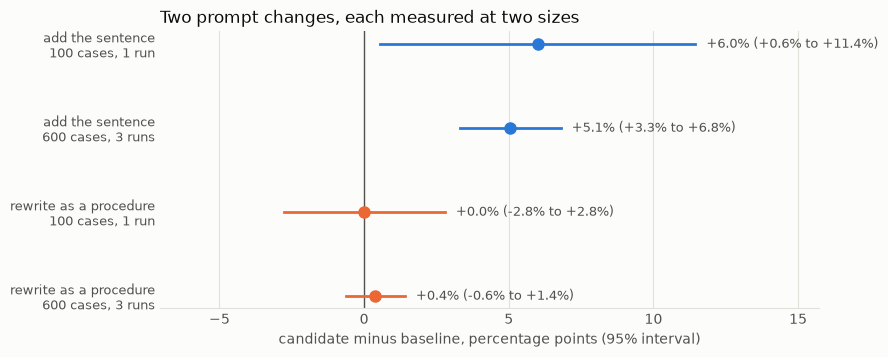

In [25]:
INK, SOFT_INK, GRID, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
COLORS = {"add the sentence": "#2a78d6", "rewrite as a procedure": "#eb6834"}

fig, ax = plt.subplots(figsize=(8.5, 3.6), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.axvline(0, color=SOFT_INK, linewidth=1)
labels = []
for change, (baseline, candidate) in CHANGES.items():
    for size, estimate in [
        ("100 cases, 1 run", paired_diff_ci(once[baseline], once[candidate])),
        ("600 cases, 3 runs", paired_diff_ci(scores[baseline], scores[candidate])),
    ]:
        row = len(labels)
        labels.append(f"{change}\n{size}")
        ax.plot(
            [100 * estimate.low, 100 * estimate.high], [row, row], color=COLORS[change], linewidth=2
        )
        ax.plot(100 * estimate.value, row, "o", color=COLORS[change], markersize=8)
        ax.annotate(
            f"{estimate:+.1%}",
            (100 * estimate.high, row),
            xytext=(8, 0),
            textcoords="offset points",
            va="center",
            color=SOFT_INK,
            fontsize=9,
        )
ax.set_yticks(range(len(labels)), labels, fontsize=9)
ax.invert_yaxis()
ax.set_xlabel("candidate minus baseline, percentage points (95% interval)", color=SOFT_INK)
ax.set_title("Two prompt changes, each measured at two sizes", loc="left", color=INK)
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
ax.tick_params(colors=SOFT_INK, length=0)
ax.margins(x=0.3)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
plt.show()

The two rows for each change estimate the same quantity. For the sentence, the small eval put the gain anywhere from 0.6 to 11.4 points, and the full run narrows it to 3.3 to 6.8. For the procedure rewrite both intervals straddle zero, and what changes is how large an effect, in either direction, is still possible.

### Where the sentence helps

An interval says whether two prompts differ. A breakdown by policy rule says where, which is what you need to improve a prompt further. Each attempt is tagged with the rule that decides its case, and the table counts wrong attempts out of three per case.

In [26]:
rule_of = {case.case_id: ruling(case) for case in cases}
attempts = pd.DataFrame(rows)
attempts["rule"] = attempts["case_id"].map(lambda case_id: rule_of[case_id][1])
attempts["wrong"] = attempts["decision"] != attempts["case_id"].map(
    lambda case_id: rule_of[case_id][0]
)

by_rule = attempts.pivot_table(index="rule", columns="prompt", values="wrong", aggfunc="sum")
by_rule = by_rule[list(PROMPTS)].astype(int)
by_rule.insert(0, "attempts", attempts[attempts["prompt"] == "draft"].groupby("rule").size())
by_rule.loc["all rules"] = by_rule.sum()
by_rule.sort_values("draft", ascending=False)

prompt,attempts,draft,prose,procedure
rule,,,,
all rules,1800,127,36,29
eligible,447,31,11,2
gift_card,99,27,3,17
grocery_reported_late,123,15,6,3
damage_reported_late,120,13,8,3
opened_electronics,120,13,0,0
seller_fault_too_late,105,13,5,0
not_returnable,177,7,0,1
outside_window,111,5,0,0


In [27]:
mistakes = attempts[attempts["wrong"]].assign(
    expected=lambda frame: frame["case_id"].map(lambda case_id: rule_of[case_id][0])
)
mistakes.pivot_table(
    index=["expected", "decision"], columns="prompt", values="wrong", aggfunc="sum", fill_value=0
)[list(PROMPTS)].astype(int)

prompt             draft  prose  procedure
expected decision                         
approve  deny         12      4          0
         escalate     19      7          2
deny     approve       8     10          6
         escalate     85     12         18
escalate approve       2      1          3
         deny          1      2          0

Adding the sentence cut escalation across the board. Under the `draft` prompt, 85 of the 127 wrong attempts are requests the policy denies and the model escalated, and another 19 are requests it should have approved and escalated. With the sentence, those fall from 85 to 12 and from 19 to 7. A plausible reading is that with no instruction for requests outside the rules, the model treats a specialist as the safe choice. That is a hypothesis: the run records decisions, not reasons. The run also cannot say which half of the sentence did the work, the limit on the specialist or the explicit default, because both were added together. Separating them would take a fourth prompt.

The tables also show what the overall tie between `prose` and `procedure` hides. The rewrite nearly removes the mistakes on requests that should be approved (11 wrong attempts down to 2), and it makes more mistakes on gift cards (17 against 3, spread over 10 of the 33 gift-card cases). The two movements partly offset each other, which leaves the totals at 36 and 29. The gift-card change is the one to look into before adopting the rewrite. It is also one row picked out of 12 after looking, so treat it as a lead to confirm on fresh cases, not as a finding.

## Step 9: Turn it into a release gate

The verdict is a function of the interval, so it can run without a person reading a chart. `evaluation/run_eval.py` wraps this notebook's analysis in a command with an exit code, which is the contract a CI job needs. It has two modes, for the two questions a prompt change raises:

- `--require better`, the default, passes when the whole interval is above zero. Use it for a change that is supposed to improve quality.
- `--require not-worse` passes when the interval rules out a drop larger than `--margin`, 2 points by default. Use it for a change made for another reason: a shorter prompt, a cheaper model, a refactor.

An interval too wide to tell fails both. A gate that passed whenever no regression was *detected* would wave through anything measured on a small enough eval.

The cell below runs the gate three times on the recorded results.

In [28]:
from evaluation.run_eval import main as release_gate

for arguments in (
    ["--baseline", "draft", "--candidate", "prose"],
    ["--baseline", "prose", "--candidate", "procedure"],
    ["--baseline", "prose", "--candidate", "procedure", "--require", "not-worse"],
):
    print("$ python evaluation/run_eval.py", " ".join(arguments))
    exit_code = release_gate(arguments)
    print("exit code:", exit_code, "\n")

$ python evaluation/run_eval.py --baseline draft --candidate prose
cases: 600 (0 left out), runs: 3
     draft: 92.9% (91.2% to 94.7%)
     prose: 98.0% (97.2% to 98.8%)
difference: +5.1% (+3.3% to +6.8%), p < 0.001
verdict: prose is better
gate: pass
exit code: 0 

$ python evaluation/run_eval.py --baseline prose --candidate procedure


cases: 600 (0 left out), runs: 3
     prose: 98.0% (97.2% to 98.8%)
 procedure: 98.4% (97.6% to 99.2%)
difference: +0.4% (-0.6% to +1.4%), p = 0.453
verdict: procedure is inconclusive
if the true difference were the +0.4% seen here, confirming it would take about 8,368 cases (a rough guide: that figure is itself noisy)
gate: fail
exit code: 1 

$ python evaluation/run_eval.py --baseline prose --candidate procedure --require not-worse
cases: 600 (0 left out), runs: 3
     prose: 98.0% (97.2% to 98.8%)
 procedure: 98.4% (97.6% to 99.2%)
difference: +0.4% (-0.6% to +1.4%), p = 0.453
verdict: procedure is inconclusive
largest drop the interval allows: -0.6%
gate: pass
exit code: 0 



The sentence passes the `better` gate. The procedure rewrite fails it and passes `not-worse`, because the low end of its interval, -0.6 points, is inside the 2-point margin. On the first 100 cases alone the same `not-worse` check would have failed: that interval reached -2.8.

## Conclusion

Two changes to one prompt, measured on 600 cases with three runs each for $0.57:

- **Adding one sentence** about requests that no rule allows improved the score by 5.1 points (+3.3 to +6.8).
- **Rewriting the policy as a procedure** changed it by +0.4 points (-0.6 to +1.4): not a measurable improvement, with a drop of more than about 0.6 points ruled out.

On the first 100 cases, read once, the first change was borderline and the second could not be told apart from a 2.8-point drop. More data settled both. Four habits tell you how much data you need and how to read it, each backed by a function you can reuse:

- **Report an interval, never a bare score** (`mean_ci`). At 100 cases a score here is uncertain by 3 to 5 points, which is as much as the change that mattered was worth.
- **Compare on the same cases and look at the difference** (`paired_diff_ci`, with `sign_test_p` when few cases differ). Read the interval three ways: better, worse, or not yet known. For the last, read how large an effect it still allows.
- **Measure how much of the noise is between runs** (`variance_components`, `projected_margin`). New cases always tighten an interval more than reruns for the same number of requests. Reruns earn their place when cases are expensive and the run-to-run share is large, as it was here: more than half for a single-run comparison.
- **Size the eval for the effect you care about, run it through the Message Batches API, and gate on the interval** (`required_cases`, `batch_runner.py`, `evaluation/run_eval.py`).

### Limits to keep in mind

- **Cases must look like production.** An interval describes the kind of case you sampled. These cases are synthetic and concentrated near the policy's thresholds, so the scores say nothing about accuracy on a real refund queue.
- **Scores near 0% or 100% on few cases** break the normal approximation, as the intervals past 100% in Step 3 showed. The bootstrap is the check: in Step 8 it agreed with the formula at full size.
- **Related cases are not independent.** If several cases come from one document or one conversation, the group is the unit, and you need clustered standard errors, which Miller's paper describes.
- **Trying many prompts inflates false positives.** At a 95% level, one comparison in twenty between identical prompts looks like a difference. If you test ten candidates and ship the best, confirm it on fresh cases.

### Applying this to your eval

Nothing here depends on the refund task. Any eval that gives a score per case and per run fits: put the scores in an array shaped `(cases, runs)` and call the same functions. A graded score between 0 and 1, such as a rubric score from a model grader, works without changes, apart from `sign_test_p`, which looks only at which prompt did better on each case.

### Next steps

- [Building evals](https://github.com/anthropics/claude-cookbooks/blob/main/misc/building_evals.ipynb), for writing the cases and graders this method needs
- [Batch processing](https://github.com/anthropics/claude-cookbooks/blob/main/misc/batch_processing.ipynb), for more on the Message Batches API
- [Adding Error Bars to Evals](https://arxiv.org/abs/2411.00640), for the derivations, clustered standard errors, and further ways to reduce variance